# Investigando ocorrências aeronáuticas no Brasil com Python

**Desafio 2 do Programa Trilhas 2026 - Trilha de Ciência de Dados: "Investigue uma pergunta com Python"**
Base: Ocorrências Aeronáuticas, ANAC / CENIPA (dados abertos)
Autor: **José Emanuel Figueredo Lopes Lacerda**

Este notebook segue as 5 etapas do processo (carregar e limpar → explorar → descrever → testar → comunicar), organizadas nas 8 seções da entrega final:

1. A base escolhida
2. As perguntas
3. Preparação dos dados
4. Análise
5. Estatística e visualizações
6. Teste de hipótese
7. Conclusões
8. Reflexão

> Regra que segui do começo ao fim: **todo número citado no texto vem de uma célula de código executada neste notebook.**

## 1. A base escolhida

**Qual base?** `V_OCORRENCIA_AMPLA.csv`: o painel de **Ocorrências Aeronáuticas** publicado pela ANAC com base nas investigações do **CENIPA** (Centro de Investigação e Prevenção de Acidentes Aeronáuticos), disponível no Portal Brasileiro de Dados Abertos (dados.gov.br).

**O que cada linha representa?** Um registro de ocorrência classificada como **Acidente** ou **Incidente Grave**, com informações sobre a data e o local, a aeronave (categoria, modelo, peso máximo de decolagem, assentos), o tipo de operação, a fase do voo, os danos e as lesões das pessoas a bordo e de terceiros. Na seção 3 vou mostrar que a unidade exata de cada linha é um pouco mais sutil do que parece.

**Período:** há registros de 1959 a junho de 2024, mas quase tudo é posterior a 1999. Para análises temporais uso a janela **2009–2023**: são 15 anos completos e o volume de registros é estável.

**Por que essa base?**
- Ela é real, pública e oficial, e tem bem mais que 300 linhas (5.021 linhas × 45 colunas).
- Tem os problemas típicos de dados reais (nulos escritos como texto, vírgula decimal, linhas repetidas), o que é bom para praticar limpeza.
- Os dados têm uso direto em decisões de segurança de voo, prevenção e seguro.

> O arquivo original fica **intocado** em `dados/V_OCORRENCIA_AMPLA.csv`. Nada é salvo por cima dele; toda a limpeza acontece em memória, numa cópia.

## 2. As perguntas

| # | Pergunta | Quem usa a resposta para decidir |
|---|----------|----------------------------------|
| **P1** | **Evolução temporal e geográfica:** o número de ocorrências por ano (2009–2023) está subindo ou caindo? Existe sazonalidade por mês? Quais regiões/UFs concentram mais ocorrências? | **ANAC/CENIPA** decidem onde e quando concentrar fiscalização e campanhas de prevenção. **Seguradoras** usam a tendência e a região para precificar risco. |
| **P2** | **Operação × fase do voo:** em que tipo de operação e em que fase do voo as ocorrências mais acontecem? Quais combinações (Operação × Fase) concentram mais acidentes? | **Escolas de aviação** escolhem as fases que pedem mais treino. **Operadores** (agrícola, táxi aéreo) revisam seus procedimentos. **CENIPA** direciona recomendações de segurança. |
| **P3** 🧪 | **Teste de hipótese (dois grupos):** a proporção de ocorrências com pelo menos uma vítima fatal é diferente entre **Voo Privado** e **Operação Agrícola**? | **ANAC** e **seguradoras** comparam a gravidade entre segmentos. Operadores agrícolas e a aviação privada geral podem ter perfis de risco diferentes, e a resposta indica onde investir em prevenção. |

A P3 compara dois grupos e é respondida com um **teste qui-quadrado de independência**, conferido com um teste z de duas proporções.

## 3. Preparação dos dados

### 3.1 Bibliotecas e configurações

In [1]:
# Bibliotecas usadas no projeto
import numpy as np                 # cálculos numéricos
import pandas as pd                # tabelas (DataFrames): filtros, agrupamentos
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estatísticos (uso no heatmap)
from scipy import stats            # testes estatísticos
from pathlib import Path

# Exibição das tabelas: mostrar todas as colunas e números com 2 casas
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Estilo dos gráficos: fundo limpo, grade discreta, fonte legível
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10.5,
})
# Paleta: azul para série única; azul + laranja para comparar dois grupos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8986"

# Pasta onde as figuras serão salvas
PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)

def salvar(fig, nome):
    # Salva a figura em figuras/<nome>.png
    fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight", dpi=150)

### 3.2 Carregamento: por que cada parâmetro?

Ao abrir o arquivo num editor de texto encontrei quatro peculiaridades, e cada uma vira um parâmetro do `read_csv`:

| Peculiaridade | Parâmetro |
|---|---|
| A 1ª linha é `Atualizado em: ...`, não o cabeçalho | `skiprows=1` |
| As colunas são separadas por `;` | `sep=";"` |
| O arquivo é UTF-8 com BOM (um caractere invisível no início) | `encoding="utf-8-sig"` |
| Valores ausentes aparecem como o texto `"null"` ou como vazio | `na_values=["null", ""]` |

O caminho é **relativo** (`dados/...`), então o notebook roda em qualquer computador que tenha a mesma estrutura de pastas.

In [2]:
CAMINHO = "dados/V_OCORRENCIA_AMPLA.csv"

df_raw = pd.read_csv(
    CAMINHO,
    sep=";",
    skiprows=1,
    encoding="utf-8-sig",
    na_values=["null", ""],
)

# A 1ª linha do arquivo diz quando a base foi atualizada; vou registrá-la
with open(CAMINHO, encoding="utf-8-sig") as f:
    print(f.readline().strip())

print("Dimensões (linhas, colunas):", df_raw.shape)
df_raw.head(3)

Atualizado em: 2026-11-25
Dimensões (linhas, colunas): (5021, 45)


,Numero_da_Ocorrencia,Numero_da_Ficha,Operador_Padronizado,Classificacao_da_Ocorrencia,Data_da_Ocorrencia,Hora_da_Ocorrencia,Municipio,UF,Regiao,Descricao_do_Tipo,ICAO,Latitude,Longitude,Tipo_de_Aerodromo,Historico,Matricula,Categoria_da_Aeronave,Operador,Tipo_de_Ocorrencia,Fase_da_Operacao,Operacao,Danos_a_Aeronave,Aerodromo_de_Destino,Aerodromo_de_Origem,Lesoes_Fatais_Tripulantes,Lesoes_Fatais_Passageiros,Lesoes_Fatais_Terceiros,Lesoes_Graves_Tripulantes,Lesoes_Graves_Passageiros,Lesoes_Graves_Terceiros,Lesoes_Leves_Tripulantes,Lesoes_Leves_Passageiros,Lesoes_Leves_Terceiros,Ilesos_Tripulantes,Ilesos_Passageiros,Lesoes_Desconhecidas_Tripulantes,Lesoes_Desconhecidas_Passageiros,Lesoes_Desconhecidas_Terceiros,Modelo,CLS,Tipo_ICAO,PMD,Numero_de_Assentos,Nome_do_Fabricante,PSSO
0,5255,/2008,GETULIO GONCALVES VIANA,Acidente,2008-03-23,NaN,NaN,MT,Centro-Oeste,FALHA OU MAU FUNCIONAMENTO DO MOTOR,NaN,"-30,9989","-54,6722",NaN,AERONAVE PERDEU POTÊNCIA EM VÔO APÓS REALIZAR ...,PTUUC,TPP,GETULIO GONCALVES VIANA,SCF-PP,NaN,Operação Agrícola,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,EMB-202A,L1P,IPAN,"1,800.00",1.00,NEIVA,verdadeiro
1,5254,/2008,NEP - NACIONAL ESCOLA DE PILOTAGEM LTDA,Acidente,2008-03-17,NaN,NaN,Indeterminado,NaN,PERDA DE CONTROLE EM VOO,NaN,NaN,NaN,NaN,A ANV PT-YFV ESTAVA REALIZANDO O SEGUNDO VÔO D...,PTYFV,PRI,NEP - NACIONAL ESCOLA DE PILOTAGEM LTD,LOC-I,NaN,Voo de Instrução,NaN,SBJR,SBJR,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,0.00,0.00,0.00,R22,H1P,R22,590.00,2.00,ROBINSON HELICOPTER,verdadeiro
2,5253,/2008,ADOLFO AMARO FILHO,Acidente,2008-03-07,NaN,NaN,Indeterminado,NaN,FALHA OU MAU FUNCIONAMENTO DO MOTOR,NaN,NaN,NaN,NaN,"APÓS A DEP, QUANDO REDUZIU O MOTOR E RECOLHEU ...",PTREB,TPP,ADOLFO AMARO FILHO,SCF-PP,Subida,Voo Privado,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,1.00,5.00,0.00,0.00,0.00,EMB-720C,L1P,PA32,"1,542.00",7.00,NEIVA,verdadeiro


### 3.3 Diagnóstico ANTES da limpeza

Antes de mexer em qualquer coisa, olhei tipos, nulos e duplicatas. Guardei `df_raw` sem alterações para comparar o antes e o depois.

In [3]:
print("Shape:", df_raw.shape)
print("Linhas 100% duplicadas:", df_raw.duplicated().sum())
print("\nTipos de cada coluna:")
print(df_raw.dtypes.to_string())

Shape: (5021, 45)
Linhas 100% duplicadas: 10

Tipos de cada coluna:
Numero_da_Ocorrencia                  int64
Numero_da_Ficha                         str
Operador_Padronizado                    str
Classificacao_da_Ocorrencia             str
Data_da_Ocorrencia                      str
Hora_da_Ocorrencia                      str
Municipio                               str
UF                                      str
Regiao                                  str
Descricao_do_Tipo                       str
ICAO                                    str
Latitude                                str
Longitude                               str
Tipo_de_Aerodromo                       str
Historico                               str
Matricula                               str
Categoria_da_Aeronave                   str
Operador                                str
Tipo_de_Ocorrencia                      str
Fase_da_Operacao                        str
Operacao                                str
Danos_a_

In [4]:
# Ausentes por coluna: quantidade e percentual (ordenado do maior para o menor)
nulos_antes = pd.DataFrame({
    "ausentes": df_raw.isna().sum(),
    "% ausentes": (df_raw.isna().mean() * 100).round(1),
}).sort_values("ausentes", ascending=False)
nulos_antes

,ausentes,% ausentes
Tipo_de_Aerodromo,3449,68.70
ICAO,3334,66.40
Aerodromo_de_Destino,2138,42.60
Aerodromo_de_Origem,2117,42.20
Latitude,1490,29.70
Longitude,1490,29.70
Hora_da_Ocorrencia,1433,28.50
Danos_a_Aeronave,1426,28.40
Municipio,1394,27.80
Lesoes_Desconhecidas_Terceiros,1327,26.40


Pontos de atenção do diagnóstico:
- `Data_da_Ocorrencia`, `Latitude` e `Longitude` foram lidas como **texto** e precisam de conversão.
- Alguns campos têm muitos ausentes: `Tipo_de_Aerodromo` (~69%), `ICAO` (~66%), aeródromos de origem/destino (~43%), coordenadas (~30%), hora (~29%), danos (~28%), fase da operação e lesões (~26%).
- Há **10 linhas 100% duplicadas**.

### 3.4 Investigando o `Numero_da_Ocorrencia` repetido (antes de remover qualquer coisa)

O número da ocorrência deveria identificar uma ocorrência, mas ele se repete. A hipótese inicial era que *ocorrências com mais de uma aeronave geram mais de uma linha*. Vou testar essa hipótese com os dados antes de decidir o que fazer.

In [5]:
sem_dup = df_raw.drop_duplicates()   # só para investigar; ainda não é a limpeza

print("Números de ocorrência distintos:", sem_dup["Numero_da_Ocorrencia"].nunique())
print("Linhas cujo número se repete (além da 1ª):", sem_dup["Numero_da_Ocorrencia"].duplicated().sum())

# Peguei só as ocorrências que aparecem em mais de uma linha
repetidas = sem_dup[sem_dup["Numero_da_Ocorrencia"].duplicated(keep=False)]
print("Ocorrências com mais de uma linha:", repetidas["Numero_da_Ocorrencia"].nunique())

# Pergunta-chave: dentro de uma mesma ocorrência, QUAIS colunas mudam de uma linha para outra?
# nunique() > 1 indica que a coluna varia dentro do grupo. A média dá a % de ocorrências em que isso acontece.
varia = (repetidas.groupby("Numero_da_Ocorrencia")
                  .nunique(dropna=False)
                  .gt(1)
                  .mean()
                  .mul(100)
                  .round(1)
                  .sort_values(ascending=False))
print("\n% das ocorrências repetidas em que a coluna muda entre as linhas:")
print(varia[varia > 0].to_string())

Números de ocorrência distintos: 4301
Linhas cujo número se repete (além da 1ª): 710
Ocorrências com mais de uma linha: 634

% das ocorrências repetidas em que a coluna muda entre as linhas:
Descricao_do_Tipo                  88.20
Tipo_de_Ocorrencia                 88.20
Operador                           12.90
Operador_Padronizado               12.90
Matricula                           5.70
Modelo                              5.40
PMD                                 4.90
Nome_do_Fabricante                  4.70
Tipo_ICAO                           4.60
Numero_de_Assentos                  4.10
CLS                                 3.60
Ilesos_Tripulantes                  3.30
Aerodromo_de_Origem                 2.80
Fase_da_Operacao                    2.80
Aerodromo_de_Destino                2.50
Categoria_da_Aeronave               2.50
Ilesos_Passageiros                  2.40
Operacao                            2.40
Lesoes_Fatais_Tripulantes           1.10
Danos_a_Aeronave              

In [6]:
# E dentro do par (ocorrência, matrícula da aeronave)? Se a hipótese "várias aeronaves"
# explicasse tudo, as linhas de um mesmo par deveriam ser idênticas.
chave = ["Numero_da_Ocorrencia", "Matricula"]
pares_rep = sem_dup[sem_dup.duplicated(chave, keep=False)]
varia_par = (pares_rep.groupby(chave, dropna=False).nunique(dropna=False)
                      .gt(1).mean().mul(100).round(1))
print("Pares (ocorrência, aeronave) com mais de uma linha:", pares_rep.groupby(chave).ngroups)
print("\nColunas que variam dentro do mesmo par (ocorrência, aeronave):")
print(varia_par[varia_par > 0].sort_values(ascending=False).to_string())

lesoes_cols = [c for c in sem_dup.columns if c.startswith(("Lesoes", "Ilesos"))]
print("\nAlguma coluna de lesões varia dentro do par?", bool(varia_par[lesoes_cols].gt(0).any()))

# Exemplo concreto: uma ocorrência com 1 aeronave e 2 tipos de ocorrência
exemplo = pares_rep["Numero_da_Ocorrencia"].iloc[0]
sem_dup.loc[sem_dup["Numero_da_Ocorrencia"] == exemplo,
            ["Numero_da_Ocorrencia", "Matricula", "Tipo_de_Ocorrencia", "Descricao_do_Tipo",
             "Operacao", "Fase_da_Operacao", "Lesoes_Fatais_Tripulantes"]]

Pares (ocorrência, aeronave) com mais de uma linha: 603

Colunas que variam dentro do mesmo par (ocorrência, aeronave):
Descricao_do_Tipo      93.00
Tipo_de_Ocorrencia     93.00
Operador_Padronizado    9.10
Operador                9.10

Alguma coluna de lesões varia dentro do par? False


,Numero_da_Ocorrencia,Matricula,Tipo_de_Ocorrencia,Descricao_do_Tipo,Operacao,Fase_da_Operacao,Lesoes_Fatais_Tripulantes
17,5240,PTVIR,LOC-G,PERDA DE CONTROLE NO SOLO,Táxi Aéreo,NaN,0.00
18,5240,PTVIR,RE,EXCURSÃO DE PISTA,Táxi Aéreo,NaN,0.00


In [7]:
# Quantas ocorrências envolvem de fato mais de uma aeronave?
aeronaves_por_ocorr = sem_dup.groupby("Numero_da_Ocorrencia")["Matricula"].nunique()
print("Ocorrências com 2 ou mais aeronaves:", (aeronaves_por_ocorr >= 2).sum())
print("Pares distintos (ocorrência, aeronave):", sem_dup.drop_duplicates(chave).shape[0])

Ocorrências com 2 ou mais aeronaves: 36
Pares distintos (ocorrência, aeronave): 4338


**O que descobri (e por que importa):**

A hipótese inicial explica **só uma pequena parte** das repetições. Na maioria dos casos, a mesma ocorrência com a **mesma aeronave** aparece em várias linhas, e a única coluna que muda é o **`Tipo_de_Ocorrencia`** (com sua descrição; às vezes também a grafia do operador). Um acidente pode ser classificado em mais de um tipo ao mesmo tempo, por exemplo "falha de motor" **e** "perda de controle em voo", e cada tipo gera uma linha.

Então o grão real da base é: **1 linha = 1 tipo de ocorrência × 1 aeronave × 1 ocorrência.**

**Decisões de limpeza:**
1. **Removi apenas as 10 duplicatas exatas.** Linhas idênticas em todas as 45 colunas não trazem informação nova. As demais repetições **são informação** (os vários tipos de uma ocorrência) e ficam na base limpa `df`.
2. A **unidade de análise** das perguntas é a **aeronave envolvida em uma ocorrência**. Para chegar a ela criei a visão `df_aeronave`, com uma linha por par (ocorrência, matrícula). Isso não apaga dados: como mostrei acima, nesse par todas as outras colunas (operação, fase, danos, lesões, data) são idênticas entre as linhas. Sem esse passo, um acidente com 3 tipos seria contado 3 vezes, e suas fatalidades também.
3. Para contar **ocorrências** (P1: por ano, mês, UF) uso `df_ocorrencia`, com uma linha por `Numero_da_Ocorrencia`.
4. As frequências de `Tipo_de_Ocorrencia` usam `df`, que é o único nível em que todos os tipos aparecem.

### 3.5 Limpeza e transformação

Tudo é feito numa **cópia** (`df = df_raw.copy()`). Cada passo está comentado.

In [8]:
df = df_raw.copy()   # trabalho sempre na cópia; df_raw fica intacto

# (1) Duplicatas exatas: remover
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"(1) Duplicatas exatas removidas: {n_antes - len(df)}")

# (2) Datas: texto 'AAAA-MM-DD' -> datetime; derivar ano, mês e dia da semana
df["Data_da_Ocorrencia"] = pd.to_datetime(df["Data_da_Ocorrencia"], format="%Y-%m-%d", errors="coerce")
print(f"(2) Datas que não puderam ser convertidas: {df['Data_da_Ocorrencia'].isna().sum()}")
df["ano"] = df["Data_da_Ocorrencia"].dt.year
df["mes"] = df["Data_da_Ocorrencia"].dt.month
DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
df["dia_semana"] = pd.Categorical(df["Data_da_Ocorrencia"].dt.day_of_week.map(dict(enumerate(DIAS))),
                                  categories=DIAS, ordered=True)

# (3) Hora: texto 'HH:MM:SS' -> extrair só a hora (0-23); ausentes continuam ausentes
df["hora"] = pd.to_datetime(df["Hora_da_Ocorrencia"], format="%H:%M:%S", errors="coerce").dt.hour

# (4) Latitude/Longitude: vírgula decimal ('-30,9989') -> ponto -> float
for col in ["Latitude", "Longitude"]:
    texto = df[col].astype("string").str.strip().str.replace(",", ".", regex=False)
    df[col] = pd.to_numeric(texto, errors="coerce")
print(f"(4) Coordenadas válidas: {df['Latitude'].notna().sum()} de {len(df)}")
fora = ~df["Latitude"].between(-35, 6) | ~df["Longitude"].between(-75, -28)
print(f"    Coordenadas fora do retângulo do Brasil (podem ser ocorrências no exterior): "
      f"{(fora & df['Latitude'].notna()).sum()}")

# (5) Códigos que significam "sem informação" -> NaN
df["Tipo_de_Aerodromo"] = df["Tipo_de_Aerodromo"].replace("-", np.nan)
df["UF"] = df["UF"].replace("Indeterminado", np.nan)

# (6) Padronização de textos
df["Categoria_da_Aeronave"] = df["Categoria_da_Aeronave"].str.upper()   # 'Estrangeira' x 'ESTRANGEIRA'
df["Fase_da_Operacao"] = df["Fase_da_Operacao"].replace({"Circuto de Tráfego": "Circuito de Tráfego"})  # erro de digitação

print("(5)(6) Códigos de 'sem informação' viraram NaN e textos foram padronizados.")

(1) Duplicatas exatas removidas: 10
(2) Datas que não puderam ser convertidas: 0
(4) Coordenadas válidas: 3521 de 5011
    Coordenadas fora do retângulo do Brasil (podem ser ocorrências no exterior): 55
(5)(6) Códigos de 'sem informação' viraram NaN e textos foram padronizados.


#### Decisão sobre as lesões ausentes (importante para o teste da P3)

As colunas `Lesoes_*` têm cerca de 26% de ausentes. **Ausente não é zero:** se não sei quantas pessoas morreram, não posso supor que ninguém morreu. Tratar o ausente como zero faria a taxa de fatalidade parecer artificialmente baixa.

Regra para a variável binária `teve_fatalidade` (soma de `Lesoes_Fatais_Tripulantes + Passageiros + Terceiros`):
- **1 (sim)**: se alguma das três colunas informadas for maior que zero. Mesmo que outra coluna esteja ausente, já sei que houve pelo menos uma morte.
- **0 (não)**: somente se **as três** colunas estiverem informadas e todas valerem zero.
- **NaN (desconhecido)**: nos demais casos. Essas linhas ficam **fora** do teste.

Na seção 6 também rodo o teste com uma regra mais rígida (excluir qualquer linha com alguma coluna fatal ausente) para verificar se a conclusão muda.

In [9]:
FATAIS = ["Lesoes_Fatais_Tripulantes", "Lesoes_Fatais_Passageiros", "Lesoes_Fatais_Terceiros"]

# Soma ignorando ausentes, mas só se houver pelo menos 1 coluna informada (min_count=1)
df["total_fatais"] = df[FATAIS].sum(axis=1, min_count=1)

alguma_positiva = (df[FATAIS] > 0).any(axis=1)          # pelo menos uma coluna > 0
todas_informadas = df[FATAIS].notna().all(axis=1)       # nenhuma coluna ausente

df["teve_fatalidade"] = np.select(
    [alguma_positiva, todas_informadas],   # condições testadas em ordem
    [1, 0],                                # 1 = houve morte; 0 = certeza de que não houve
    default=np.nan,                        # caso contrário: desconhecido
)
# total_fatais só faz sentido quando o desfecho é conhecido
df.loc[df["teve_fatalidade"].isna(), "total_fatais"] = np.nan

print(df["teve_fatalidade"].value_counts(dropna=False).rename({1.0: "sim (1)", 0.0: "não (0)"}))

teve_fatalidade
não (0)    3017
NaN        1161
sim (1)     833
Name: count, dtype: int64


### 3.6 Diagnóstico DEPOIS da limpeza (comparação com o antes)

In [10]:
print("Shape antes:", df_raw.shape, "| depois:", df.shape)
print("Duplicatas exatas antes:", df_raw.duplicated().sum(), "| depois:", df.duplicated().sum())

# Comparação de tipos para as colunas que mudaram
mudou = [c for c in df_raw.columns if df_raw[c].dtype != df[c].dtype]
print("\nColunas cujo tipo mudou:")
print(pd.DataFrame({"antes": df_raw[mudou].dtypes.astype(str), "depois": df[mudou].dtypes.astype(str)}).to_string())
novas = [c for c in df.columns if c not in df_raw.columns]
print("\nColunas novas:", novas)
print(df[novas].dtypes.to_string())

Shape antes: (5021, 45) | depois: (5011, 51)
Duplicatas exatas antes: 10 | depois: 0

Colunas cujo tipo mudou:
                   antes          depois
Data_da_Ocorrencia   str  datetime64[us]
Latitude             str         Float64
Longitude            str         Float64

Colunas novas: ['ano', 'mes', 'dia_semana', 'hora', 'total_fatais', 'teve_fatalidade']
ano                   int32
mes                   int32
dia_semana         category
hora                float64
total_fatais        float64
teve_fatalidade     float64


In [11]:
# Ausentes antes x depois (as colunas que mudaram de quantidade aparecem com diferença ≠ 0)
nulos = pd.DataFrame({
    "ausentes_antes": df_raw.isna().sum(),
    "ausentes_depois": df[df_raw.columns].isna().sum(),
})
nulos["diferença"] = nulos["ausentes_depois"] - nulos["ausentes_antes"]
nulos["% depois"] = (nulos["ausentes_depois"] / len(df) * 100).round(1)
nulos.sort_values("ausentes_depois", ascending=False)

,ausentes_antes,ausentes_depois,diferença,% depois
Tipo_de_Aerodromo,3449,4242,793,84.70
ICAO,3334,3332,-2,66.50
Aerodromo_de_Destino,2138,2133,-5,42.60
Aerodromo_de_Origem,2117,2112,-5,42.10
Latitude,1490,1490,0,29.70
Longitude,1490,1490,0,29.70
Hora_da_Ocorrencia,1433,1433,0,28.60
Danos_a_Aeronave,1426,1426,0,28.50
Municipio,1394,1394,0,27.80
Lesoes_Desconhecidas_Terceiros,1327,1319,-8,26.30


Na tabela, a coluna "diferença" fica negativa nas colunas que perderam as 10 duplicatas e positiva em `UF` e `Tipo_de_Aerodromo`, onde os códigos `Indeterminado` e `-` passaram a contar como ausentes. **Não preenchi (imputei) nenhum ausente.** Cada análise usa as linhas que têm a informação de que precisa e informa quantas linhas usou.

### 3.7 As três visões da base (níveis de granularidade)

In [12]:
CHAVE = ["Numero_da_Ocorrencia", "Matricula"]

# Visão por aeronave envolvida em uma ocorrência (unidade de análise das perguntas)
df_aeronave = df.drop_duplicates(CHAVE).reset_index(drop=True)

# Visão por ocorrência (para contar ocorrências no tempo e no espaço)
df_ocorrencia = df.drop_duplicates("Numero_da_Ocorrencia").reset_index(drop=True)

print(f"df             : {len(df):>5} linhas  (tipo de ocorrência × aeronave × ocorrência)")
print(f"df_aeronave    : {len(df_aeronave):>5} linhas  (aeronave × ocorrência)  <- unidade de análise")
print(f"df_ocorrencia  : {len(df_ocorrencia):>5} linhas  (ocorrência)")
print(f"\nPeríodo: {df['Data_da_Ocorrencia'].min():%d/%m/%Y} a {df['Data_da_Ocorrencia'].max():%d/%m/%Y}")
print(f"Ocorrências entre 2009 e 2023: {df_ocorrencia['ano'].between(2009, 2023).sum()} "
      f"({df_ocorrencia['ano'].between(2009, 2023).mean():.1%} do total)")

df             :  5011 linhas  (tipo de ocorrência × aeronave × ocorrência)
df_aeronave    :  4338 linhas  (aeronave × ocorrência)  <- unidade de análise
df_ocorrencia  :  4301 linhas  (ocorrência)

Período: 11/01/1959 a 22/06/2024
Ocorrências entre 2009 e 2023: 3418 (79.5% do total)


## 4. Análise

Nesta seção uso **filtros** (`df[condição]`), **agrupamentos** (`groupby`, `value_counts`) e **tabelas cruzadas** (`pd.crosstab`) do Pandas. Os gráficos de cada pergunta estão na seção 5.

### P1. Evolução temporal e geográfica

Janela de **2009 a 2023**. O ano de 2024 está incompleto (os dados vão só até junho) e ficaria artificialmente baixo, e antes de 2009 o volume de registros é bem menor, o que sugere outra cobertura de notificação.

In [13]:
# Filtro: apenas ocorrências de 2009 a 2023
oc = df_ocorrencia[df_ocorrencia["ano"].between(2009, 2023)].copy()

# Agrupamento: ocorrências por ano, separando Acidente e Incidente Grave
por_ano = pd.crosstab(oc["ano"], oc["Classificacao_da_Ocorrencia"])
por_ano["Total"] = por_ano.sum(axis=1)
por_ano

Classificacao_da_Ocorrencia,Acidente,Incidente Grave,Total
ano,,,
2009,116,15,131
2010,132,64,196
2011,187,65,252
2012,209,80,289
2013,203,69,272
2014,177,75,252
2015,173,50,223
2016,167,48,215
2017,148,54,202


In [14]:
# Tendência: regressão linear simples (ocorrências ~ ano).
# A inclinação diz quantas ocorrências a mais (ou a menos) há por ano, em média.
tend = stats.linregress(por_ano.index, por_ano["Total"])
print(f"Inclinação: {tend.slope:+.1f} ocorrências/ano | R² = {tend.rvalue**2:.2f} | valor-p = {tend.pvalue:.3f}")

# Comparação simples: média dos 5 primeiros anos x média dos 5 últimos
ini = por_ano.loc[2009:2013, "Total"].mean()
fim = por_ano.loc[2019:2023, "Total"].mean()
print(f"Média 2009-2013: {ini:.1f} | Média 2019-2023: {fim:.1f} | variação: {fim/ini - 1:+.1%}")

# Tendência separada a partir de 2012 (depois do salto de 2009-2011)
t12 = stats.linregress(por_ano.loc[2012:].index, por_ano.loc[2012:, "Total"])
print(f"Só 2012-2023 -> inclinação: {t12.slope:+.1f}/ano | valor-p = {t12.pvalue:.3f}")

# A tendência é a mesma para acidentes e incidentes graves? (2012-2023)
for classe in ["Acidente", "Incidente Grave"]:
    r = stats.linregress(por_ano.loc[2012:].index, por_ano.loc[2012:, classe])
    print(f"  {classe:<16} 2012-2023: {r.slope:+.1f}/ano | valor-p = {r.pvalue:.3f} | "
          f"{por_ano.loc[2012, classe]} em 2012 -> {por_ano.loc[2023, classe]} em 2023")

Inclinação: +1.0 ocorrências/ano | R² = 0.01 | valor-p = 0.680
Média 2009-2013: 228.0 | Média 2019-2023: 227.6 | variação: -0.2%
Só 2012-2023 -> inclinação: -4.5/ano | valor-p = 0.027
  Acidente         2012-2023: -5.4/ano | valor-p = 0.000 | 209 em 2012 -> 156 em 2023
  Incidente Grave  2012-2023: +0.9/ano | valor-p = 0.481 | 80 em 2012 -> 58 em 2023


In [15]:
# Sazonalidade: média de ocorrências em cada mês, calculada sobre os 15 anos
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
mes_ano = oc.groupby(["ano", "mes"]).size().unstack(fill_value=0)   # linhas = ano, colunas = mês
saz = pd.DataFrame({
    "média/ano": mes_ano.mean(),
    "desvio padrão": mes_ano.std(),
    "total 15 anos": mes_ano.sum(),
})
saz.index = MESES
saz["% do total"] = (saz["total 15 anos"] / saz["total 15 anos"].sum() * 100).round(1)
saz

,média/ano,desvio padrão,total 15 anos,% do total
Jan,22.67,4.39,340,9.90
Fev,21.07,5.02,316,9.20
Mar,20.13,4.84,302,8.80
Abr,20.87,4.93,313,9.20
Mai,19.00,5.28,285,8.30
Jun,14.20,3.91,213,6.20
Jul,17.93,4.71,269,7.90
Ago,17.20,5.89,258,7.50
Set,18.73,5.08,281,8.20
Out,17.87,4.63,268,7.80


In [16]:
# A sazonalidade é igual em todas as operações? % das ocorrências de cada operação que cai em cada mês
saz_op = (pd.crosstab(oc["mes"], oc["Operacao"], normalize="columns") * 100)[["Voo Privado", "Operação Agrícola", "Voo de Instrução"]]
saz_op.index = MESES
saz_op.round(1)

Operacao,Voo Privado,Operação Agrícola,Voo de Instrução
Jan,8.20,18.30,6.40
Fev,7.70,15.10,8.00
Mar,7.90,12.00,8.90
Abr,9.70,8.20,9.70
Mai,9.40,6.30,6.20
Jun,7.10,2.80,8.00
Jul,9.30,2.70,10.70
Ago,8.10,2.20,10.70
Set,9.70,2.40,8.30
Out,8.00,5.20,8.30


In [17]:
# Dia da semana (complemento da sazonalidade)
oc["dia_semana"].value_counts().reindex(DIAS).to_frame("ocorrências")

,ocorrências
dia_semana,
Segunda,399
Terça,454
Quarta,494
Quinta,479
Sexta,545
Sábado,590
Domingo,457


In [18]:
# Geografia: ocorrências por região e por UF (UF ausente/indeterminada fica de fora e é contada)
print("Ocorrências sem UF identificada (2009-2023):", oc["UF"].isna().sum())
reg = oc["Regiao"].value_counts().to_frame("ocorrências")
reg["%"] = (reg["ocorrências"] / reg["ocorrências"].sum() * 100).round(1)
reg

Ocorrências sem UF identificada (2009-2023): 62


,ocorrências,%
Regiao,,
Sudeste,1124,33.60
Centro-Oeste,740,22.10
Sul,628,18.80
Norte,496,14.80
Nordeste,357,10.70


In [19]:
uf = oc["UF"].value_counts().to_frame("ocorrências")
uf["%"] = (uf["ocorrências"] / uf["ocorrências"].sum() * 100).round(1)
uf["% acumulado"] = uf["%"].cumsum().round(1)
uf.head(10)

,ocorrências,%,% acumulado
UF,,,
SP,657,19.60,19.60
MT,300,8.90,28.50
MG,286,8.50,37.00
RS,270,8.00,45.00
GO,262,7.80,52.80
PR,248,7.40,60.20
PA,214,6.40,66.60
RJ,148,4.40,71.00
MS,145,4.30,75.30


### P2. Tipo de operação e fase do voo

Unidade: **aeronave envolvida em uma ocorrência** (`df_aeronave`), usando a base inteira.

In [20]:
def freq(serie, nome):
    # Tabela de frequência com contagem, % e % acumulado (ausentes contados à parte)
    t = serie.value_counts().to_frame(nome)
    t["%"] = (t[nome] / t[nome].sum() * 100).round(1)
    t["% acumulado"] = t["%"].cumsum().round(1)
    return t

print("Operação ausente:", df_aeronave["Operacao"].isna().sum())
freq(df_aeronave["Operacao"], "aeronaves")

Operação ausente: 87


,aeronaves,%,% acumulado
Operacao,,,
Voo Privado,1973,46.40,46.40
Operação Agrícola,754,17.70,64.10
Voo de Instrução,605,14.20,78.30
Táxi Aéreo,457,10.80,89.10
Voo Regular,134,3.20,92.30
Operação Pública,112,2.60,94.90
Operação Especializada,100,2.40,97.30
Voo Experimental,65,1.50,98.80
Operação Policial,18,0.40,99.20


In [21]:
print("Fase ausente:", df_aeronave["Fase_da_Operacao"].isna().sum(),
      f"({df_aeronave['Fase_da_Operacao'].isna().mean():.1%})")
freq(df_aeronave["Fase_da_Operacao"], "aeronaves").head(15)

Fase ausente: 1246 (28.7%)


,aeronaves,%,% acumulado
Fase_da_Operacao,,,
Pouso,624,20.20,20.20
Decolagem,503,16.30,36.50
Em rota,349,11.30,47.80
Corrida após pouso,336,10.90,58.70
Manobra,221,7.10,65.80
Cruzeiro,148,4.80,70.60
Subida,147,4.80,75.40
Especializada,137,4.40,79.80
Aproximação,134,4.30,84.10


In [22]:
# Os tipos de ocorrência usam df (nível tipo × aeronave × ocorrência), pois uma aeronave pode ter vários
tipos = (df.dropna(subset=["Tipo_de_Ocorrencia"])
           .groupby(["Tipo_de_Ocorrencia", "Descricao_do_Tipo"]).size()
           .sort_values(ascending=False).head(10).to_frame("registros"))
tipos

,,registros
Tipo_de_Ocorrencia,Descricao_do_Tipo,
SCF-PP,FALHA OU MAU FUNCIONAMENTO DO MOTOR,779
RE,EXCURSÃO DE PISTA,649
LOC-I,PERDA DE CONTROLE EM VOO,534
LOC-G,PERDA DE CONTROLE NO SOLO,475
SCF-NP,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPONENTE,454
OTHR,OUTROS,268
CTOL,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,219
ARC,CONTATO ANORMAL COM A PISTA,193
UNK,INDETERMINADO,175


In [23]:
# Combinações Operação × Fase, só ACIDENTES e com fase conhecida
acid = df_aeronave[(df_aeronave["Classificacao_da_Ocorrencia"] == "Acidente")
                   & df_aeronave["Fase_da_Operacao"].notna()
                   & (df_aeronave["Fase_da_Operacao"] != "Indeterminada")
                   & df_aeronave["Operacao"].notna()]
print("Acidentes com operação e fase conhecidas:", len(acid))

combos = acid.groupby(["Operacao", "Fase_da_Operacao"]).size().sort_values(ascending=False).to_frame("acidentes")
combos["% dos acidentes"] = (combos["acidentes"] / len(acid) * 100).round(1)
combos["% acumulado"] = combos["% dos acidentes"].cumsum().round(1)
combos.head(10)

Acidentes com operação e fase conhecidas: 2059


acidentes  % dos acidentes  % acumulado
Operacao          Fase_da_Operacao                                           
Voo Privado       Pouso                     188             9.10         9.10
                  Em rota                   172             8.40        17.50
                  Decolagem                 168             8.20        25.70
Operação Agrícola Decolagem                 125             6.10        31.80
                  Especializada             123             6.00        37.80
                  Manobra                   108             5.20        43.00
Voo Privado       Corrida após pouso         83             4.00        47.00
                  Subida                     71             3.40        50.40
Voo de Instrução  Pouso                      64             3.10        53.50
Voo Privado       Cruzeiro                   53             2.60        56.10

In [24]:
# Dentro de cada operação, qual fase concentra mais acidentes? (% na linha)
top_ops = acid["Operacao"].value_counts().head(5).index
fase_por_op = (pd.crosstab(acid["Operacao"], acid["Fase_da_Operacao"], normalize="index") * 100)
fase_dominante = pd.DataFrame({
    "fase mais frequente": fase_por_op.loc[top_ops].idxmax(axis=1),
    "% dos acidentes da operação": fase_por_op.loc[top_ops].max(axis=1).round(1),
    "n acidentes": acid["Operacao"].value_counts().loc[top_ops],
})
fase_dominante

,fase mais frequente,% dos acidentes da operação,n acidentes
Operacao,,,
Voo Privado,Pouso,19.50,966
Operação Agrícola,Decolagem,24.70,506
Voo de Instrução,Pouso,25.00,256
Táxi Aéreo,Pouso,23.80,143
Voo Regular,Pouso,26.00,50


### P3. Exploração inicial: fatalidade por tipo de operação

Antes do teste formal, comparo descritivamente a taxa de fatalidade das principais operações. As linhas com fatalidade desconhecida (`teve_fatalidade` ausente) ficam de fora.

In [25]:
conhecido = df_aeronave[df_aeronave["teve_fatalidade"].notna()]
taxa_op = (conhecido.groupby("Operacao")["teve_fatalidade"]
                    .agg(n="size", com_fatalidade="sum", taxa="mean")
                    .query("n >= 50")
                    .sort_values("taxa", ascending=False))
taxa_op["taxa"] = (taxa_op["taxa"] * 100).round(1)
taxa_op = taxa_op.rename(columns={"taxa": "% com fatalidade"})
taxa_op["com_fatalidade"] = taxa_op["com_fatalidade"].astype(int)
taxa_op

,n,com_fatalidade,% com fatalidade
Operacao,,,
Operação Especializada,81,25,30.90
Voo Privado,1629,480,29.50
Táxi Aéreo,407,81,19.90
Operação Agrícola,559,110,19.70
Operação Pública,100,14,14.00
Voo Regular,115,10,8.70
Voo de Instrução,510,43,8.40


## 5. Estatística e visualizações

### 5.1 Estatística descritiva

**Tendência central** (média, mediana) e **dispersão** (desvio padrão, amplitude, quartis) das principais variáveis numéricas.

In [26]:
# Ocorrências por ano (2009-2023)
serie_ano = por_ano["Total"]
resumo_ano = pd.Series({
    "média": serie_ano.mean(),
    "mediana": serie_ano.median(),
    "desvio padrão": serie_ano.std(),
    "mínimo": serie_ano.min(),
    "máximo": serie_ano.max(),
    "coef. de variação (%)": serie_ano.std() / serie_ano.mean() * 100,
}, name="ocorrências por ano (2009-2023)")
resumo_ano.to_frame()

,ocorrências por ano (2009-2023)
média,227.87
mediana,224.00
desvio padrão,36.83
mínimo,131.00
máximo,289.00
coef. de variação (%),16.16


In [27]:
# Vítimas fatais por aeronave-ocorrência (só onde o desfecho é conhecido)
fatais = df_aeronave["total_fatais"].dropna()
print("Todas as aeronave-ocorrências com desfecho conhecido:")
print(fatais.describe().rename({"count": "n", "mean": "média", "std": "desvio padrão", "min": "mínimo",
                                "50%": "mediana", "max": "máximo"}).to_string())
print(f"\nSomente as que tiveram ao menos 1 morte (n = {(fatais > 0).sum()}):")
print(f"  média = {fatais[fatais > 0].mean():.2f} | mediana = {fatais[fatais > 0].median():.0f} | "
      f"desvio padrão = {fatais[fatais > 0].std():.2f} | máximo = {fatais.max():.0f}")

Todas as aeronave-ocorrências com desfecho conhecido:
n               3,492.00
média               0.59
desvio padrão       4.48
mínimo              0.00
25%                 0.00
mediana             0.00
75%                 0.00
máximo            199.00

Somente as que tiveram ao menos 1 morte (n = 792):
  média = 2.59 | mediana = 2 | desvio padrão = 9.13 | máximo = 199


In [28]:
# Porte da aeronave por tipo de operação: PMD (peso máximo de decolagem, kg) e nº de assentos
ops_princ = ["Voo Privado", "Operação Agrícola", "Voo de Instrução", "Táxi Aéreo", "Voo Regular"]
porte = (df_aeronave[df_aeronave["Operacao"].isin(ops_princ)]
         .groupby("Operacao")[["PMD", "Numero_de_Assentos"]]
         .agg(["mean", "median", "std"])
         .reindex(ops_princ))
porte.columns = [f"{v} - {e}" for v, e in porte.columns]
porte = porte.rename(columns=lambda c: c.replace("mean", "média").replace("median", "mediana")
                                         .replace("std", "desvio padrão").replace("Numero_de_Assentos", "Assentos"))
porte

,PMD - média,PMD - mediana,PMD - desvio padrão,Assentos - média,Assentos - mediana,Assentos - desvio padrão
Operacao,,,,,,
Voo Privado,"1,716.85","1,406.00","1,413.55",4.67,4.00,2.84
Operação Agrícola,"1,951.28","1,800.00",689.66,1.33,1.00,5.30
Voo de Instrução,857.42,770.00,417.22,2.55,2.00,1.35
Táxi Aéreo,"3,363.02","2,155.00","7,140.91",7.97,7.00,3.95
Voo Regular,"61,478.52","61,234.00","52,675.92",127.63,125.00,72.47


No **Táxi Aéreo** a média do PMD fica bem acima da mediana e o desvio padrão é o dobro da média. É uma distribuição **assimétrica**: poucas aeronaves grandes puxam a média para cima, e nesse caso a **mediana** representa melhor a aeronave típica. No Voo Regular, média e mediana são parecidas porque a frota é mais homogênea (jatos comerciais). Na Operação Agrícola, o desvio padrão dos assentos é maior que a média de quase 1 assento, o que indica **valores atípicos**, provavelmente erros de cadastro numa frota que é quase toda monoposto.

### 5.2 Tabelas de frequência

In [29]:
for col in ["Classificacao_da_Ocorrencia", "Danos_a_Aeronave", "Categoria_da_Aeronave"]:
    print(f"\n=== {col} (ausentes: {df_aeronave[col].isna().sum()}) ===")
    print(freq(df_aeronave[col], "aeronaves").head(8).to_string())


=== Classificacao_da_Ocorrencia (ausentes: 0) ===
                             aeronaves     %  % acumulado
Classificacao_da_Ocorrencia                              
Acidente                          3275 75.50        75.50
Incidente Grave                   1063 24.50       100.00

=== Danos_a_Aeronave (ausentes: 1364) ===
                  aeronaves     %  % acumulado
Danos_a_Aeronave                              
Substancial            1835 61.70        61.70
Leve                    550 18.50        80.20
Destruída               308 10.40        90.60
Nenhum                  265  8.90        99.50
Desconhecida             16  0.50       100.00

=== Categoria_da_Aeronave (ausentes: 8) ===
                       aeronaves     %  % acumulado
Categoria_da_Aeronave                              
TPP                         1592 36.80        36.80
PRI                          601 13.90        50.70
S05                          545 12.60        63.30
PET                          471 10.90  

### 5.3 Gráficos

Todos os gráficos têm título, eixos e legenda em português e também ficam salvos em `figuras/`.

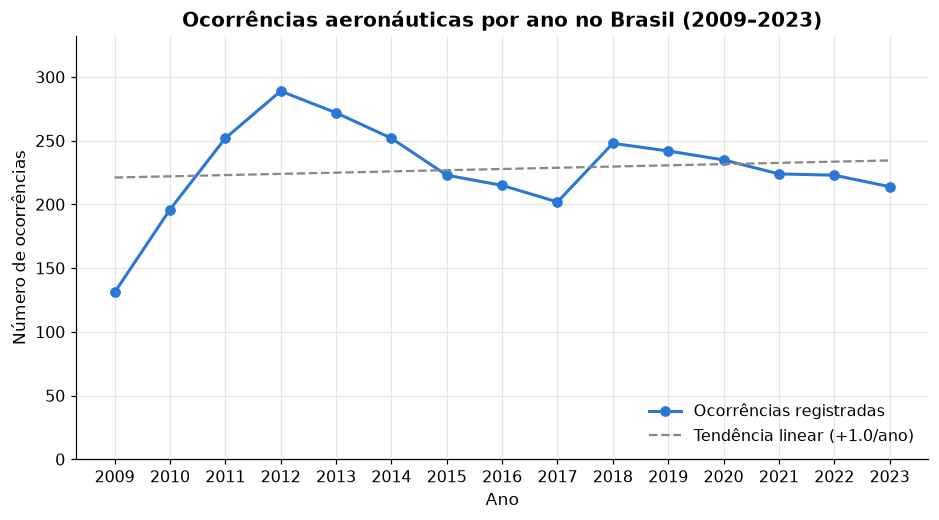

In [30]:
# Gráfico 1: linha temporal do total com a reta de tendência
fig, ax = plt.subplots()
ax.plot(serie_ano.index, serie_ano.values, color=AZUL, lw=2, marker="o", ms=6, label="Ocorrências registradas")
ax.plot(serie_ano.index, tend.intercept + tend.slope * serie_ano.index, color=CINZA, lw=1.5, ls="--",
        label=f"Tendência linear ({tend.slope:+.1f}/ano)")
ax.set_title("Ocorrências aeronáuticas por ano no Brasil (2009–2023)")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de ocorrências")
ax.set_xticks(serie_ano.index)
ax.set_ylim(0, serie_ano.max() * 1.15)
ax.legend(frameon=False, loc="lower right")
salvar(fig, "01_ocorrencias_por_ano")
plt.show()

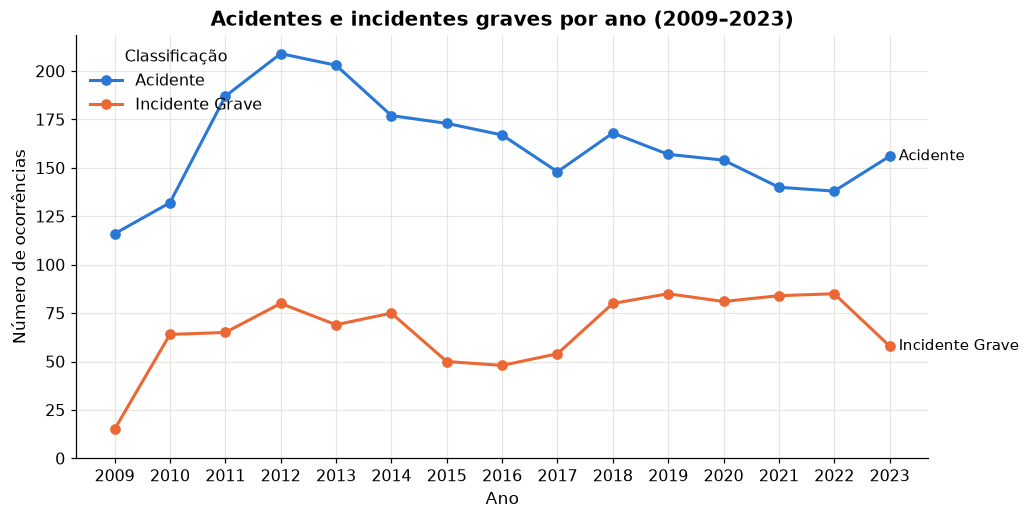

In [31]:
# Gráfico 2: Acidentes x Incidentes Graves por ano
fig, ax = plt.subplots()
for classe, cor in [("Acidente", AZUL), ("Incidente Grave", LARANJA)]:
    ax.plot(por_ano.index, por_ano[classe], color=cor, lw=2, marker="o", ms=6, label=classe)
    ax.annotate(classe, (por_ano.index[-1], por_ano[classe].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10)
ax.set_title("Acidentes e incidentes graves por ano (2009–2023)")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de ocorrências")
ax.set_xticks(por_ano.index)
ax.set_ylim(0, None)
ax.legend(title="Classificação", frameon=False, loc="upper left")
salvar(fig, "02_acidentes_incidentes_por_ano")
plt.show()

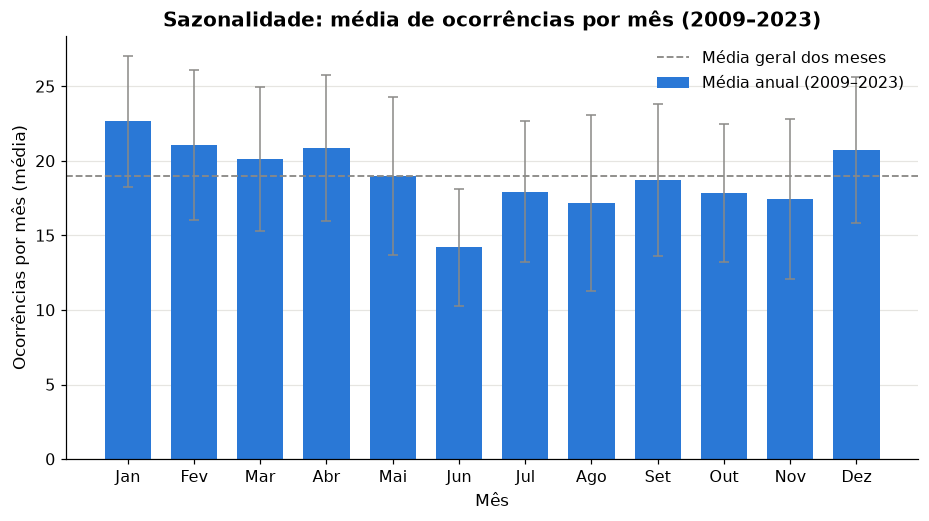

In [32]:
# Gráfico 3: sazonalidade, média de ocorrências por mês (com barra de desvio padrão)
fig, ax = plt.subplots()
ax.bar(saz.index, saz["média/ano"], color=AZUL, width=0.7, yerr=saz["desvio padrão"],
       error_kw={"ecolor": CINZA, "elinewidth": 1, "capsize": 3}, label="Média anual (2009–2023)")
ax.axhline(saz["média/ano"].mean(), color=CINZA, ls="--", lw=1.2, label="Média geral dos meses")
ax.set_title("Sazonalidade: média de ocorrências por mês (2009–2023)")
ax.set_xlabel("Mês")
ax.set_ylabel("Ocorrências por mês (média)")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
salvar(fig, "03_sazonalidade_mes")
plt.show()

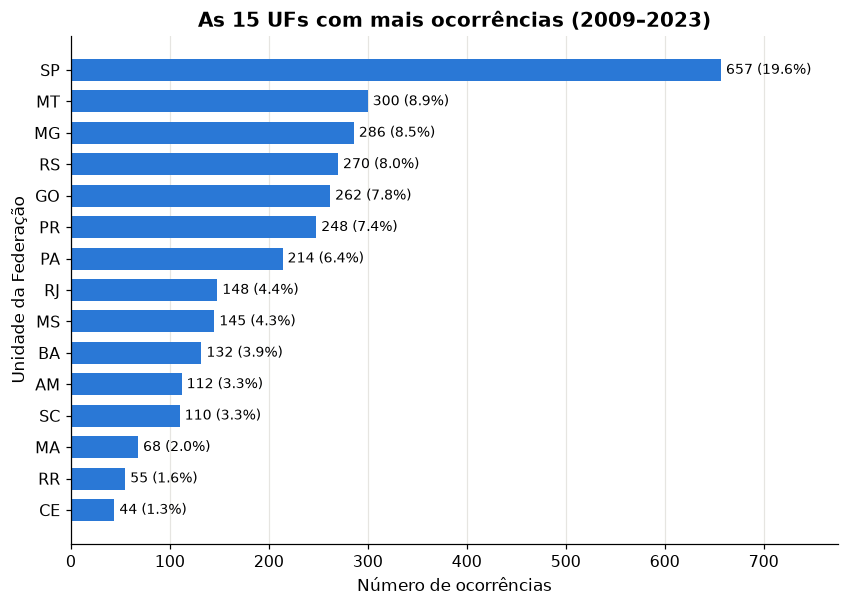

In [33]:
# Gráfico 4: as 15 UFs com mais ocorrências (barras horizontais)
top_uf = uf.head(15).iloc[::-1]   # invertido para a maior ficar no topo
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_uf.index, top_uf["ocorrências"], color=AZUL, height=0.7)
for y, (v, p) in enumerate(zip(top_uf["ocorrências"], top_uf["%"])):
    ax.text(v + 5, y, f"{v} ({p:.1f}%)", va="center", fontsize=9)
ax.set_title("As 15 UFs com mais ocorrências (2009–2023)")
ax.set_xlabel("Número de ocorrências")
ax.set_ylabel("Unidade da Federação")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top_uf["ocorrências"].max() * 1.18)
salvar(fig, "04_ocorrencias_por_uf")
plt.show()

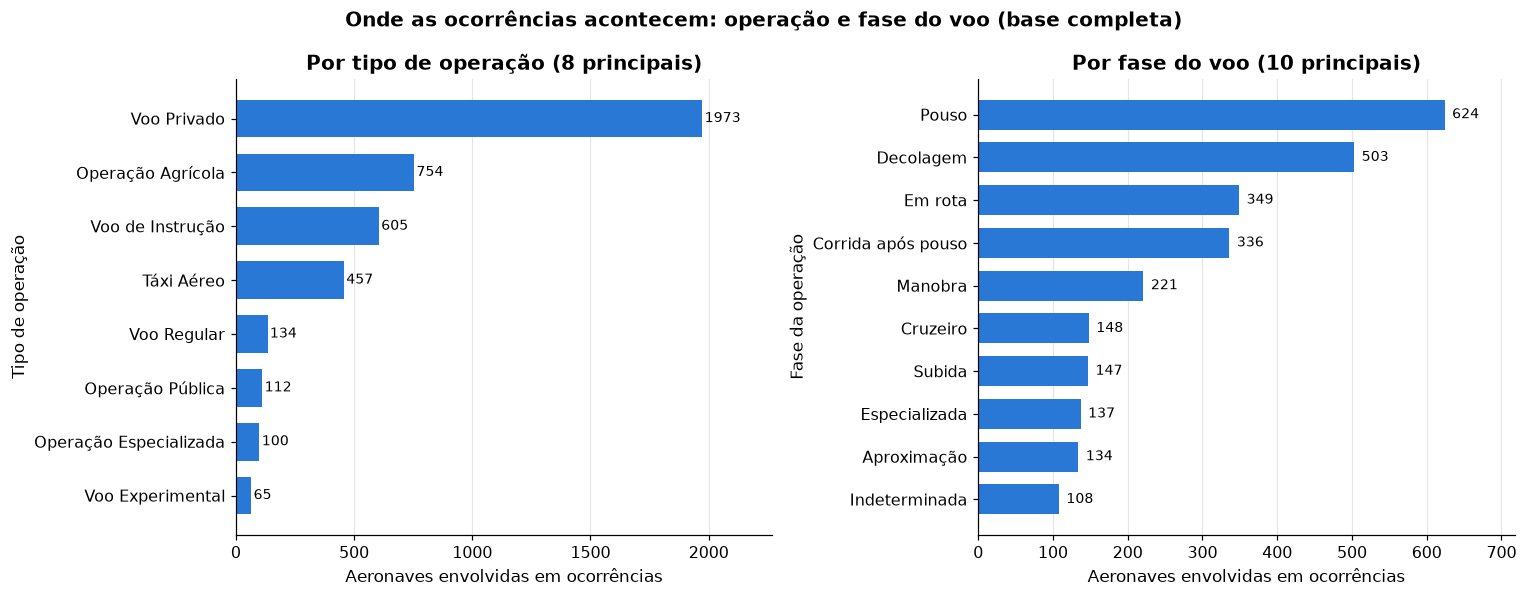

In [34]:
# Gráficos 5 e 6: operação e fase do voo (lado a lado)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ops = df_aeronave["Operacao"].value_counts().head(8).iloc[::-1]
fases = df_aeronave["Fase_da_Operacao"].value_counts().head(10).iloc[::-1]
for ax, s, titulo, ylab in [(axes[0], ops, "Por tipo de operação (8 principais)", "Tipo de operação"),
                            (axes[1], fases, "Por fase do voo (10 principais)", "Fase da operação")]:
    ax.barh(s.index, s.values, color=AZUL, height=0.7)
    for y, v in enumerate(s.values):
        ax.text(v + 10, y, f"{v}", va="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("Aeronaves envolvidas em ocorrências")
    ax.set_ylabel(ylab)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, s.max() * 1.15)
fig.suptitle("Onde as ocorrências acontecem: operação e fase do voo (base completa)", fontweight="bold", fontsize=13)
fig.tight_layout()
salvar(fig, "05_operacao_e_fase")
plt.show()

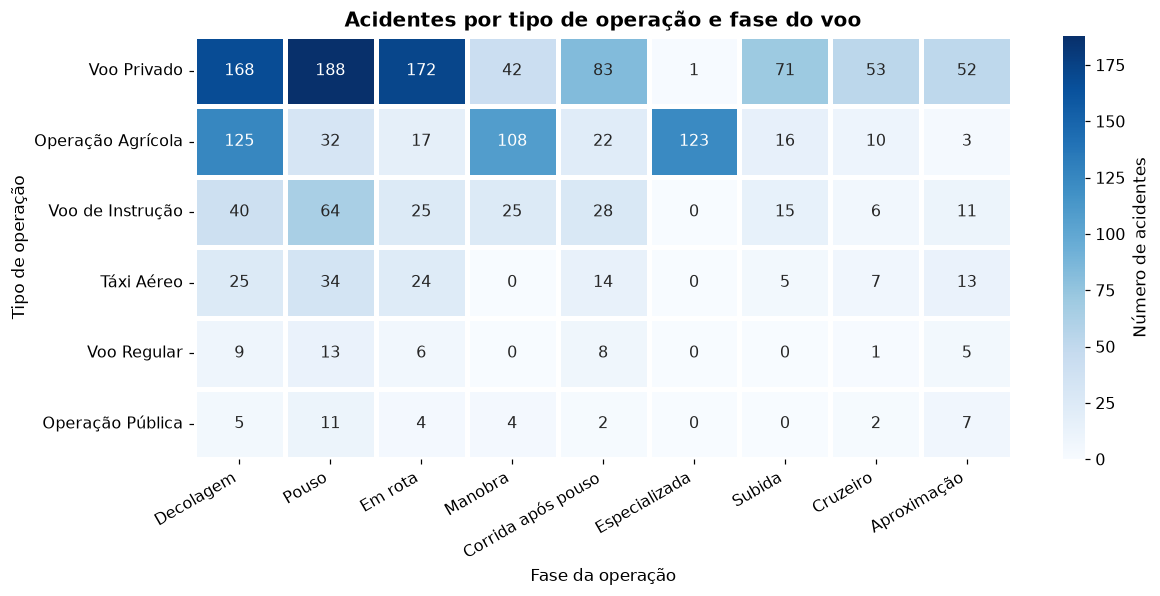

In [35]:
# Gráfico 7: heatmap Operação × Fase (apenas acidentes)
ops_hm = acid["Operacao"].value_counts().head(6).index
fases_hm = acid["Fase_da_Operacao"].value_counts().head(9).index
matriz = pd.crosstab(acid["Operacao"], acid["Fase_da_Operacao"]).loc[ops_hm, fases_hm]

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "Número de acidentes"}, ax=ax)
ax.set_title("Acidentes por tipo de operação e fase do voo")
ax.set_xlabel("Fase da operação")
ax.set_ylabel("Tipo de operação")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
salvar(fig, "06_heatmap_operacao_fase")
plt.show()

## 6. Teste de hipótese

### 6.1 A pergunta em linguagem estatística

> *A proporção de aeronaves envolvidas em ocorrências com **pelo menos uma vítima fatal** é diferente entre **Voo Privado** e **Operação Agrícola**?*

- **Variável resposta:** `teve_fatalidade` (1 = houve ao menos uma morte; 0 = não houve), criada na seção 3.5.
- **Grupos:** `Operacao == "Voo Privado"` × `Operacao == "Operação Agrícola"`.
- **H₀ (hipótese nula):** as proporções são **iguais** (p_privado = p_agrícola). Qualquer diferença observada seria fruto do acaso.
- **H₁ (hipótese alternativa):** as proporções são **diferentes** (p_privado ≠ p_agrícola). O teste é bilateral: não aposto antes em qual grupo é maior.
- **Nível de significância:** α = 0,05. Se o valor-p for menor que 0,05, rejeito H₀.
- **Teste:** qui-quadrado de independência numa tabela 2×2 (`scipy.stats.chi2_contingency`), conferido com o teste z de duas proporções. Numa tabela 2×2 e sem correção de continuidade, os dois testes são matematicamente equivalentes (z² = χ²).

**O que é o valor-p?** É a probabilidade de observar uma diferença **tão grande ou maior** que a encontrada **se H₀ fosse verdadeira**. Valor-p pequeno significa que um resultado assim seria muito improvável por puro acaso.

In [36]:
ALPHA = 0.05
GRUPOS = ["Voo Privado", "Operação Agrícola"]

base_teste = df_aeronave[df_aeronave["Operacao"].isin(GRUPOS)]

# Quantas linhas saem por fatalidade desconhecida (transparência sobre a exclusão)
exclusao = base_teste.groupby("Operacao")["teve_fatalidade"].agg(
    total="size", desconhecido=lambda s: s.isna().sum()).reindex(GRUPOS)
exclusao["% excluído"] = (exclusao["desconhecido"] / exclusao["total"] * 100).round(1)
print("Linhas excluídas por fatalidade desconhecida:")
print(exclusao.to_string())

amostra = base_teste.dropna(subset=["teve_fatalidade"])

# Tabela de contingência 2x2 (linhas = grupo, colunas = desfecho)
tabela = pd.crosstab(amostra["Operacao"], amostra["teve_fatalidade"].map({1: "Com fatalidade", 0: "Sem fatalidade"}))
tabela = tabela.loc[GRUPOS, ["Com fatalidade", "Sem fatalidade"]]
print("\nTabela de contingência (observado):")
tabela_m = tabela.copy()
tabela_m["Total"] = tabela_m.sum(axis=1)
tabela_m["% com fatalidade"] = (tabela_m["Com fatalidade"] / tabela_m["Total"] * 100).round(1)
tabela_m

Linhas excluídas por fatalidade desconhecida:
                   total  desconhecido  % excluído
Operacao                                          
Voo Privado         1973           344       17.40
Operação Agrícola    754           195       25.90

Tabela de contingência (observado):


teve_fatalidade,Com fatalidade,Sem fatalidade,Total,% com fatalidade
Operacao,,,,
Voo Privado,480,1149,1629,29.50
Operação Agrícola,110,449,559,19.70


### 6.2 Premissas do teste qui-quadrado (e verificação)

1. **Observações independentes:** cada linha é uma aeronave numa ocorrência, e cada observação pertence a um único grupo. *Ressalva:* uma mesma aeronave (matrícula) pode aparecer em ocorrências de anos diferentes, e algumas ocorrências envolvem duas aeronaves. Meço abaixo quanto isso acontece. Ocorrências diferentes da mesma aeronave costumam estar separadas por anos e ter causas distintas, então trato a premissa como **razoável, mas não perfeita**, e registro isso nas limitações.
2. **Categorias mutuamente exclusivas:** cada aeronave-ocorrência tem uma única operação e um único desfecho (sim/não).
3. **Contagens esperadas ≥ 5 em todas as células:** verifico abaixo com a tabela de frequências esperadas que o próprio `chi2_contingency` devolve.

In [37]:
chi2, p_chi2, gl, esperado = stats.chi2_contingency(tabela, correction=False)
esperado = pd.DataFrame(esperado, index=tabela.index, columns=tabela.columns)
print("Frequências ESPERADAS se H0 fosse verdadeira:")
print(esperado.round(1).to_string())
print(f"\nMenor contagem esperada: {esperado.values.min():.1f}  ->  premissa (≥ 5) atendida? {esperado.values.min() >= 5}")

# Independência: quantas matrículas se repetem na amostra? quantas ocorrências têm 2+ aeronaves?
rep_mat = amostra["Matricula"].duplicated(keep=False).sum()
rep_oc = amostra["Numero_da_Ocorrencia"].duplicated(keep=False).sum()
print(f"Linhas cuja matrícula aparece em mais de uma ocorrência: {rep_mat} de {len(amostra)} ({rep_mat/len(amostra):.1%})")
print(f"Linhas de ocorrências com 2+ aeronaves na amostra: {rep_oc}")

Frequências ESPERADAS se H0 fosse verdadeira:
teve_fatalidade    Com fatalidade  Sem fatalidade
Operacao                                         
Voo Privado                439.30        1,189.70
Operação Agrícola          150.70          408.30

Menor contagem esperada: 150.7  ->  premissa (≥ 5) atendida? True
Linhas cuja matrícula aparece em mais de uma ocorrência: 330 de 2188 (15.1%)
Linhas de ocorrências com 2+ aeronaves na amostra: 20


### 6.3 Resultado do teste

In [38]:
# --- Qui-quadrado (sem correção, equivalente ao teste z) e com correção de Yates (mais conservador)
chi2_y, p_yates, _, _ = stats.chi2_contingency(tabela, correction=True)

# --- Teste z de duas proporções (feito "à mão" para entender a conta)
x1, x2 = tabela["Com fatalidade"]            # nº com fatalidade em cada grupo
n1, n2 = tabela.sum(axis=1)                  # tamanho de cada grupo
p1, p2 = x1 / n1, x2 / n2                    # proporções observadas
p_comb = (x1 + x2) / (n1 + n2)               # proporção combinada (vale sob H0)
ep_h0 = np.sqrt(p_comb * (1 - p_comb) * (1/n1 + 1/n2))
z = (p1 - p2) / ep_h0
p_z = 2 * stats.norm.sf(abs(z))              # bilateral

# --- Tamanho do efeito
dif = p1 - p2
ep_dif = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)   # erro padrão sem supor H0 (para o IC)
ic = (dif - 1.96*ep_dif, dif + 1.96*ep_dif)     # IC de 95% da diferença
cramer_v = np.sqrt(chi2 / tabela.values.sum())  # Cramér's V (tabela 2x2: V = |phi|)
risco_rel = p1 / p2

print(f"Proporção com fatalidade - {GRUPOS[0]}: {p1:.1%}  ({x1}/{n1})")
print(f"Proporção com fatalidade - {GRUPOS[1]}: {p2:.1%}  ({x2}/{n2})")
print(f"\nQui-quadrado = {chi2:.2f} (gl = {gl}) | valor-p = {p_chi2:.2e}  (= {p_chi2:.7f})")
print(f"Com correção de Yates: qui-quadrado = {chi2_y:.2f} | valor-p = {p_yates:.2e}")
print(f"Teste z = {z:.2f} | valor-p = {p_z:.2e}   (z² = {z**2:.2f}, igual ao qui-quadrado)")
print(f"\nDiferença de proporções = {dif*100:+.1f} pontos percentuais | IC 95%: [{ic[0]*100:+.1f}; {ic[1]*100:+.1f}] p.p.")
print(f"Risco relativo = {risco_rel:.2f} (Voo Privado / Operação Agrícola)")
print(f"Cramér's V = {cramer_v:.3f}")

decisao = "REJEITO H0" if p_chi2 < ALPHA else "NÃO rejeito H0"
print(f"\nDecisão com α = {ALPHA}: valor-p {'<' if p_chi2 < ALPHA else '≥'} {ALPHA} -> {decisao}")

Proporção com fatalidade - Voo Privado: 29.5%  (480/1629)
Proporção com fatalidade - Operação Agrícola: 19.7%  (110/559)

Qui-quadrado = 20.25 (gl = 1) | valor-p = 6.81e-06  (= 0.0000068)
Com correção de Yates: qui-quadrado = 19.75 | valor-p = 8.82e-06
Teste z = 4.50 | valor-p = 6.81e-06   (z² = 20.25, igual ao qui-quadrado)

Diferença de proporções = +9.8 pontos percentuais | IC 95%: [+5.8; +13.8] p.p.
Risco relativo = 1.50 (Voo Privado / Operação Agrícola)
Cramér's V = 0.096

Decisão com α = 0.05: valor-p < 0.05 -> REJEITO H0


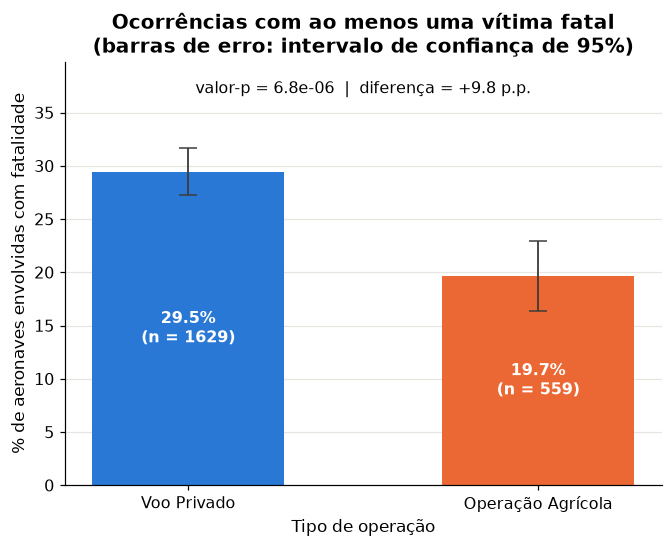

In [39]:
# Visualização: proporção com fatalidade em cada grupo, com IC de 95% (Wald)
props = pd.Series([p1, p2], index=GRUPOS)
eps = np.sqrt(props * (1 - props) / pd.Series([n1, n2], index=GRUPOS))
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(GRUPOS, props * 100, color=[AZUL, LARANJA], width=0.55,
       yerr=1.96 * eps * 100, error_kw={"ecolor": "#3d3d3a", "elinewidth": 1.2, "capsize": 6})
for i, (pp, nn) in enumerate(zip(props, [n1, n2])):
    ax.text(i, pp * 100 / 2, f"{pp:.1%}\n(n = {nn})", ha="center", va="center", color="white", fontweight="bold")
ax.set_title("Ocorrências com ao menos uma vítima fatal\n(barras de erro: intervalo de confiança de 95%)")
ax.set_ylabel("% de aeronaves envolvidas com fatalidade")
ax.set_xlabel("Tipo de operação")
ax.set_ylim(0, max(props * 100) * 1.35)
ax.text(0.5, max(props * 100) * 1.25, f"valor-p = {p_chi2:.1e}  |  diferença = {dif*100:+.1f} p.p.",
        ha="center", fontsize=10.5)
ax.grid(axis="x", visible=False)
salvar(fig, "07_teste_fatalidade")
plt.show()

### 6.4 O resultado é robusto? (análise de sensibilidade)

Um resultado confiável não deve depender de uma escolha arbitrária. Repeti o mesmo teste mudando uma decisão de cada vez:
- **Exclusão rígida:** exclui qualquer linha com **alguma** coluna fatal ausente.
- **Só acidentes:** remove os incidentes graves. A proporção de incidentes pode diferir entre os grupos e distorcer a comparação.
- **Só 2009–2023:** usa o mesmo período da P1.
- **Com correção de Yates:** versão mais conservadora do qui-quadrado.

In [40]:
def teste_2x2(dados, rotulo, correcao=False):
    # Roda o qui-quadrado 2x2 para uma versão da base e devolve um resumo em uma linha
    t = pd.crosstab(dados["Operacao"], dados["teve_fatalidade"]).loc[GRUPOS, [1.0, 0.0]]
    c2, p, _, esp = stats.chi2_contingency(t, correction=correcao)
    pr = t[1.0] / t.sum(axis=1)
    return {"cenário": rotulo, "n Privado": int(t.sum(axis=1).iloc[0]), "n Agrícola": int(t.sum(axis=1).iloc[1]),
            "% fatal Privado": round(pr.iloc[0] * 100, 1), "% fatal Agrícola": round(pr.iloc[1] * 100, 1),
            "diferença (p.p.)": round((pr.iloc[0] - pr.iloc[1]) * 100, 1),
            "valor-p": p, "menor esperado": round(esp.min(), 1), "rejeita H0?": "sim" if p < ALPHA else "não"}

rigida = base_teste[base_teste[FATAIS].notna().all(axis=1)]
sens = pd.DataFrame([
    teste_2x2(amostra, "Principal (regra da seção 3.5)"),
    teste_2x2(rigida, "Exclusão rígida de ausentes"),
    teste_2x2(amostra[amostra["Classificacao_da_Ocorrencia"] == "Acidente"], "Só acidentes"),
    teste_2x2(amostra[amostra["ano"].between(2009, 2023)], "Só 2009-2023"),
    teste_2x2(amostra, "Com correção de Yates", correcao=True),
])
sens["valor-p"] = sens["valor-p"].map(lambda p: f"{p:.2e}")
sens

,cenário,n Privado,n Agrícola,% fatal Privado,% fatal Agrícola,diferença (p.p.),valor-p,menor esperado,rejeita H0?
0,Principal (regra da seção 3.5),1629,559,29.50,19.70,9.80,6.81e-06,150.70,sim
1,Exclusão rígida de ausentes,1561,539,26.40,16.70,9.70,5.36e-06,128.80,sim
2,Só acidentes,1321,504,36.30,21.80,14.40,3.70e-09,162.70,sim
3,Só 2009-2023,1324,479,26.50,18.60,7.90,5.35e-04,116.90,sim
4,Com correção de Yates,1629,559,29.50,19.70,9.80,8.82e-06,150.70,sim


In [41]:
# Composição dos grupos: proporção de acidentes x incidentes graves (ajuda a interpretar a sensibilidade)
(pd.crosstab(amostra["Operacao"], amostra["Classificacao_da_Ocorrencia"], normalize="index") * 100).round(1).loc[GRUPOS]

Classificacao_da_Ocorrencia,Acidente,Incidente Grave
Operacao,,
Voo Privado,81.10,18.90
Operação Agrícola,90.20,9.80


### 6.5 Interpretação em linguagem simples

A célula abaixo escreve a interpretação **a partir dos números calculados**, para que o texto nunca fique diferente do resultado.

In [42]:
maior, menor = (GRUPOS[0], GRUPOS[1]) if p1 > p2 else (GRUPOS[1], GRUPOS[0])
print(f'''
• No Voo Privado, {p1:.1%} das aeronaves envolvidas em ocorrências tiveram ao menos uma vítima fatal;
  na Operação Agrícola, {p2:.1%}.
• A diferença é de {abs(dif)*100:.1f} pontos percentuais (IC 95%: {abs(ic[0])*100:.1f} a {abs(ic[1])*100:.1f} p.p.),
  ou seja, a proporção no grupo "{maior}" é {max(risco_rel, 1/risco_rel):.2f} vezes a do grupo "{menor}".
• Valor-p = {p_chi2:.2e} (≈ {p_chi2:.6f}). {"Como é menor que 0,05, rejeito H0: a diferença é real e dificilmente explicada pelo acaso." if p_chi2 < ALPHA else "Como não é menor que 0,05, não rejeito H0: a diferença pode ser acaso."}
• Tamanho do efeito: Cramér's V = {cramer_v:.2f}, uma associação {"fraca" if cramer_v < 0.3 else "moderada" if cramer_v < 0.5 else "forte"}.
  Estatisticamente significativo não é o mesmo que "enorme": a operação explica só parte da variação.
• O resultado se mantém em todos os cenários de sensibilidade? {"Sim." if (sens["rejeita H0?"] == "sim").all() else "Não, veja a tabela acima."}
''')


• No Voo Privado, 29.5% das aeronaves envolvidas em ocorrências tiveram ao menos uma vítima fatal;
  na Operação Agrícola, 19.7%.
• A diferença é de 9.8 pontos percentuais (IC 95%: 5.8 a 13.8 p.p.),
  ou seja, a proporção no grupo "Voo Privado" é 1.50 vezes a do grupo "Operação Agrícola".
• Valor-p = 6.81e-06 (≈ 0.000007). Como é menor que 0,05, rejeito H0: a diferença é real e dificilmente explicada pelo acaso.
• Tamanho do efeito: Cramér's V = 0.10, uma associação fraca.
  Estatisticamente significativo não é o mesmo que "enorme": a operação explica só parte da variação.
• O resultado se mantém em todos os cenários de sensibilidade? Sim.


## 7. Conclusões

### Números-chave (gerados pelo código)
A célula abaixo reúne os números citados nas conclusões e no README.

In [43]:
uf_top3 = uf.head(3)
reg_top = reg.iloc[0]
chave = {
    "Linhas no arquivo original": len(df_raw),
    "Ocorrências distintas (base toda)": len(df_ocorrencia),
    "Aeronave-ocorrências (base toda)": len(df_aeronave),
    "Ocorrências 2009-2023": int(serie_ano.sum()),
    "Média de ocorrências/ano (2009-2023)": round(serie_ano.mean(), 1),
    "Mediana/ano": serie_ano.median(),
    "Desvio padrão/ano": round(serie_ano.std(), 1),
    "Ano com mais ocorrências": f"{serie_ano.idxmax()} ({serie_ano.max()})",
    "Ano com menos ocorrências": f"{serie_ano.idxmin()} ({serie_ano.min()})",
    "Tendência 2009-2023 (ocorr./ano; valor-p)": f"{tend.slope:+.1f}; p = {tend.pvalue:.3f}",
    "Tendência 2012-2023 (ocorr./ano; valor-p)": f"{t12.slope:+.1f}; p = {t12.pvalue:.3f}",
    "Média 2009-2013 x 2019-2023": f"{ini:.1f} x {fim:.1f} ({fim/ini-1:+.1%})",
    "Mês com maior média": f"{saz['média/ano'].idxmax()} ({saz['média/ano'].max():.1f}/ano; {saz['% do total'].max()}%)",
    "Mês com menor média": f"{saz['média/ano'].idxmin()} ({saz['média/ano'].min():.1f}/ano; {saz['% do total'].min()}%)",
    "Região líder": f"{reg.index[0]} ({reg_top['%']}%)",
    "Top 3 UFs": ", ".join(f"{u} {p}%" for u, p in uf_top3["%"].items()),
    "Operação mais frequente": f"{ops.index[-1]} ({freq(df_aeronave['Operacao'], 'n')['%'].iloc[0]}%)",
    "Fase mais frequente": f"{fases.index[-1]} ({freq(df_aeronave['Fase_da_Operacao'], 'n')['%'].iloc[0]}% das com fase conhecida)",
    "Combinação Operação x Fase nº 1 (acidentes)": f"{combos.index[0][0]} / {combos.index[0][1]} ({combos.iloc[0, 0]}; {combos.iloc[0, 1]}%)",
    "Combinação nº 2": f"{combos.index[1][0]} / {combos.index[1][1]} ({combos.iloc[1, 0]}; {combos.iloc[1, 1]}%)",
    "Combinação nº 3": f"{combos.index[2][0]} / {combos.index[2][1]} ({combos.iloc[2, 0]}; {combos.iloc[2, 1]}%)",
    "% fatal Voo Privado": f"{p1:.1%} ({x1}/{n1})",
    "% fatal Operação Agrícola": f"{p2:.1%} ({x2}/{n2})",
    "Diferença (IC 95%)": f"{dif*100:+.1f} p.p. [{ic[0]*100:+.1f}; {ic[1]*100:+.1f}]",
    "Qui-quadrado; valor-p": f"{chi2:.2f}; {p_chi2:.2e}",
    "Cramér's V": round(cramer_v, 3),
}
pd.Series(chave, name="valor").to_frame()

,valor
Linhas no arquivo original,5021
Ocorrências distintas (base toda),4301
Aeronave-ocorrências (base toda),4338
Ocorrências 2009-2023,3418
Média de ocorrências/ano (2009-2023),227.90
Mediana/ano,224.00
Desvio padrão/ano,36.80
Ano com mais ocorrências,2012 (289)
Ano com menos ocorrências,2009 (131)
Tendência 2009-2023 (ocorr./ano; valor-p),+1.0; p = 0.680


### O que os dados mostraram

**P1: Evolução temporal e geográfica (2009–2023, 3.418 ocorrências)**
- Em média foram **227,9 ocorrências por ano** (mediana 224; desvio padrão 36,8).
- **Não há tendência linear no período inteiro** (+1,0 ocorrência/ano; valor-p = 0,680). O volume subiu de 131 (2009) para 289 (2012) e **depois caiu de forma significativa**: −4,5 por ano entre 2012 e 2023 (valor-p = 0,027), terminando em 214.
- **A queda vem dos acidentes:** passaram de 209 (2012) para 156 (2023), −5,4 por ano (valor-p < 0,001). Os **incidentes graves não têm tendência** (+0,9 por ano; valor-p = 0,481). Uma hipótese é que menos eventos estejam virando acidente, mas não dá para afirmar sem dados de exposição.
- **A sazonalidade é moderada:** janeiro tem a maior média (22,7 ocorrências/mês; 9,9% do total) e junho a menor (14,2; 6,2%). Os meses de dezembro a abril ficam acima da média mensal (19,0) e os de junho a novembro ficam abaixo.
- **Quem gera a sazonalidade é a aviação agrícola:** **61,1%** das ocorrências agrícolas acontecem entre dezembro e março (18,3% só em janeiro), o período de safra e pulverização. No Voo Privado cada mês fica entre 7,1% e 9,7%, sem padrão sazonal.
- O **sábado** é o dia com mais ocorrências (590) e a **segunda-feira** o dia com menos (399), coerente com o voo privado e de lazer nos fins de semana.
- **Geografia:** Sudeste (33,6%) e Centro-Oeste (22,1%) concentram mais da metade. As UFs líderes são **SP (19,6%), MT (8,9%) e MG (8,5%)**, e as 5 primeiras somam 52,8%. A presença de MT e GO no topo combina com a força da aviação agrícola no Centro-Oeste.

**P2: Operação × fase do voo (4.338 aeronave-ocorrências)**
- **Voo Privado** responde por **46,4%** das aeronaves envolvidas, seguido de Operação Agrícola (17,7%), Voo de Instrução (14,2%) e Táxi Aéreo (10,8%). Esses quatro segmentos somam 89,1%.
- Entre as aeronaves com fase conhecida, **Pouso (20,2%)** e **Decolagem (16,3%)** lideram. Junto com a Corrida após pouso (10,9%), quase metade das ocorrências acontece **perto do solo**.
- Entre os **2.059 acidentes** com operação e fase conhecidas, as combinações que mais concentram acidentes são **Voo Privado / Pouso (188; 9,1%)**, Voo Privado / Em rota (172; 8,4%) e Voo Privado / Decolagem (168; 8,2%). Em seguida vêm três combinações da Operação Agrícola: Decolagem (125; 6,1%), Especializada (123; 6,0%) e Manobra (108; 5,2%). Essas **6 combinações somam 43% dos acidentes**.
- Os tipos de ocorrência mais comuns são **falha de motor (SCF-PP, 779 registros)**, **excursão de pista (RE, 649)** e **perda de controle em voo (LOC-I, 534)**.

**P3: Teste de hipótese**
- **29,5%** das aeronaves de Voo Privado envolvidas em ocorrências tiveram ao menos uma vítima fatal (480 de 1.629), contra **19,7%** na Operação Agrícola (110 de 559).
- Qui-quadrado = 20,25 (gl = 1), **valor-p = 6,8 × 10⁻⁶**, menor que α = 0,05. **Rejeito H₀: a diferença é real, não acaso.**
- A diferença é de **+9,8 pontos percentuais** (IC 95%: +5,8 a +13,8). O risco relativo é **1,50** e o Cramér's V é **0,10** (efeito fraco). A diferença é real, mas o tipo de operação sozinho explica pouco da fatalidade.
- A conclusão se mantém nos 5 cenários de sensibilidade: exclusão rígida, só acidentes, só 2009–2023 e correção de Yates.

### Resultados inesperados
1. **A aviação agrícola, vista como uma das operações mais arriscadas (voo baixo, fios, obstáculos), tem MENOS fatalidade que o voo privado.** Ao restringir a análise aos **acidentes**, a diferença **aumenta** para 14,4 p.p. (36,3% contra 21,8%). Ela não é explicada pelo fato de o voo privado ter mais incidentes graves; acontece o contrário, porque 90,2% das ocorrências agrícolas são acidentes, contra 81,1% no Voo Privado. Uma explicação plausível, que **não testei**, está no porte das aeronaves: as agrícolas têm mediana de **1 assento** e as privadas de **4** (seção 5.1). Com menos pessoas a bordo há menos chance de "pelo menos uma vítima", e essas aeronaves são projetadas para resistir a impactos em baixa velocidade.
2. **Na aviação agrícola, a fase mais perigosa é a decolagem (24,7% dos acidentes agrícolas)**, mais do que a própria aplicação ("Especializada"). Faz sentido operacionalmente: a aeronave decola carregada e muitas vezes de pistas improvisadas.
3. **As linhas repetidas da base não eram, na maioria, "várias aeronaves"** (como eu supunha), e sim **vários tipos de ocorrência para a mesma aeronave**. Contar linhas direto inflaria todos os números em cerca de 15%.
4. Restringir o teste a 2009–2023 reduz a fatalidade do Voo Privado de 29,5% para 26,5%. **Os registros antigos são mais letais**, um sinal de que antes só os casos mais graves chegavam à base, ou seja, de mudança no critério ou na cobertura de notificação.

## 8. Reflexão

### O que ficou mais fácil em Python do que em planilha
- **Ler um arquivo "sujo":** com uma única linha de `read_csv` resolvi o cabeçalho extra, o `;`, o BOM e os `"null"`. Numa planilha isso exige importação manual e costuma corromper acentos e a vírgula decimal.
- **Investigar as duplicatas:** descobrir *quais colunas variam* dentro de cada número de ocorrência (`groupby(...).nunique()`) levou uma linha de código. Numa planilha seria preciso filtrar caso a caso.
- **Reprodutibilidade:** "Reiniciar e executar tudo" refaz toda a análise do zero. Se a ANAC publicar uma versão nova do arquivo, basta trocá-lo e rodar de novo. Numa planilha, cada clique é um passo que ninguém consegue auditar.
- **Base original protegida:** o CSV nunca é alterado; toda a limpeza fica documentada em código.
- **Estatística de verdade:** o teste qui-quadrado, o intervalo de confiança, o Cramér's V e a análise de sensibilidade saem com poucas linhas de `scipy`/`numpy`.
- **Gráficos padronizados:** o mesmo estilo em todas as figuras, salvas automaticamente em `figuras/`.

### Como o trabalho foi dividido
O trabalho foi **individual**. Não houve divisão de tarefas: todas as etapas (escolha da base, limpeza, análise, gráficos, teste de hipótese e comunicação dos resultados) foram feitas por mim.

### Limitações da análise
1. **Sem denominador (exposição):** a base só registra o que deu errado. Não há horas voadas, número de decolagens nem frota ativa por segmento. Mais ocorrências na Aviação Privada ou em SP podem refletir apenas **mais voos**, e não um risco maior. Por isso falo de **contagens** e de **gravidade condicional** ("dado que houve uma ocorrência, qual a chance de ter fatalidade"), nunca de "taxa de acidentes por hora de voo".
2. **Viés de seleção:** a base contém só **acidentes e incidentes graves**. Incidentes comuns e quase-acidentes ficam de fora, então não vejo o universo completo de eventos de segurança.
3. **Mudança de critério de notificação ao longo do tempo:** o salto de registros entre 2009 e 2012 e o volume baixíssimo antes de 1999 sugerem mudanças de cobertura, de sistema ou de critério. Uma tendência pode refletir **como se registra**, e não só **quanto acontece**. Além disso, 2024 está incompleto.
4. **Dados ausentes:** cerca de 29% das aeronave-ocorrências sem fase de voo e, nos grupos testados, 17% (Voo Privado) e 26% (Operação Agrícola) sem desfecho de fatalidade conhecido. Os grupos perdem proporções diferentes de linhas. Se os ausentes não forem aleatórios (por exemplo, casos ainda em investigação), as proporções podem ter viés. A análise de sensibilidade reduz essa preocupação, mas não a elimina.
5. **Granularidade da base:** cada linha é um *tipo de ocorrência*, não uma ocorrência. Por isso trabalhei com três visões (seção 3.7). Contar linhas diretamente inflaria os números em cerca de 15%.
6. **Independência imperfeita:** cerca de 15% das linhas do teste são de aeronaves que aparecem em mais de uma ocorrência. O teste supõe observações independentes, então o valor-p pode estar um pouco otimista. Como ele é muito menor que 0,05, a conclusão dificilmente mudaria.
7. **Associação não é causa:** o teste mostra que fatalidade e tipo de operação estão associados, mas não explica por quê. Porte da aeronave, perfil do piloto, ambiente (pistas não preparadas, voo baixo) e a mistura entre acidentes e incidentes graves podem estar por trás da diferença.
8. **Base quase censitária:** o teste trata os registros como amostra de um processo que gera ocorrências. A pergunta que ele responde é "essa diferença é maior do que a variação esperada ao acaso?", e não "qual é a proporção numa população maior".